In [1]:
import pya
from pya import *
import SiEPIC
from SiEPIC._globals import Python_Env
from SiEPIC.scripts import connect_cell, connect_pins_with_waveguide, zoom_out, export_layout
from SiEPIC.utils import create_cell2, get_layout_variables
from SiEPIC.utils.layout import new_layout, floorplan, coupler_array
from SiEPIC.extend import to_itype
from SiEPIC.verification import layout_check
import numpy as np
from SiEPIC.scripts import connect_pins_with_waveguide, connect_cell
import os
import sys



KLayout SiEPIC-Tools version 0.5.31
SiEPIC-Tools is up to date (0.5.31 vs 0.5.31).
Version check, time: 0.10314607620239258 seconds


In [2]:

if Python_Env == 'Script':

    # Define the path to your local PDK
    path_to_pdk = r"D:\GitHub"
    # path_GitHub = r"C:\Users\gamem\OneDrive - UBC\Documents\GitHub"

    sys.path.insert(0, os.path.join(path_to_pdk, "SiEPICfab-EBeam-ZEP-PDK"))

    # Now try importing the PDK
    import SiEPICfab_EBeam_ZEP



SiEPICfab-EBeam-ZEP Python module: siepicfab_ebeam_zep, KLayout technology: SiEPICfab_EBeam_ZEP
SiEPICfab-EBeam-ZEP Python module: pymacros, v0.1.5
Libraries associated with Technology SiEPICfab_EBeam_ZEP: ['SiEPICfab_EBeam_ZEP', 'SiEPICfab_EBeam_ZEP_Beta', 'SiEPICfab_EBeam_ZEP_Superconducting', 'SiEPICfab_EBeam_ZEP_pkirwin']
Libraries associated with Technology SiEPICfab_EBeam_ZEP: ['SiEPICfab_EBeam_ZEP', 'SiEPICfab_EBeam_ZEP_Beta', 'SiEPICfab_EBeam_ZEP_Superconducting', 'SiEPICfab_EBeam_ZEP_pkirwin']


In [3]:
tech_name = 'SiEPICfab_EBeam_ZEP'  # Can change this
gclib_name = 'SiEPICfab_EBeam_ZEP_Superconducting'
lib_name = 'SiEPICfab_EBeam_ZEP_Beta'

top_cell_name = 'SinglePassRing'  # Change this to the name of the top cell from the floorplan

chip_name = 'SiEPICfab_ZEP_2603'  # Change this to the name of the .oas file from the folder gds_floorplan
chip_folder = 'SiEPICfab_ZEP_SNSPDPASSIVE_202504'


chip_file = os.path.join("gds_floorplan", f"{chip_name}.oas")  # Main chip file in floorplan
layout_file = os.path.join("designs", f"{top_cell_name}.oas")  # Name of the soon-to-be chip


In [4]:
"""
This script is used to extract a cell from a floorplan and save it as a GDS file.
Worry less about it, just run it and it will do the job.
"""

_, _ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
_ly.read(chip_file)
_top_cell = _ly.cell(top_cell_name)
_top_cell.write(layout_file) #save the layout to a GDS file

In [5]:
"""
This script is used to open a GDS file and display it in KLayout.
Creates a new layout and reads the GDS file the above cell made.
"""


_, ly = new_layout(tech_name, "test", GUI=True, overwrite = False)
ly.read(layout_file)
# Access the top cell
top_cell = ly.cell(top_cell_name)

dbu = ly.dbu
wg_bend_radius = 20
              

top_cell.plot() # in the browser
top_cell.show() # in KLayout

Could not connect to klive server. Is klayout open and klive plugin installed?


In [6]:
top_cell.bbox().width()*dbu, top_cell.bbox().height()*dbu, top_cell.bbox().right, top_cell.bbox().top # just useful to confirm the size of the cell

(2285.0, 2400.0, 2285000, 2400000)

Could not connect to klive server. Is klayout open and klive plugin installed?


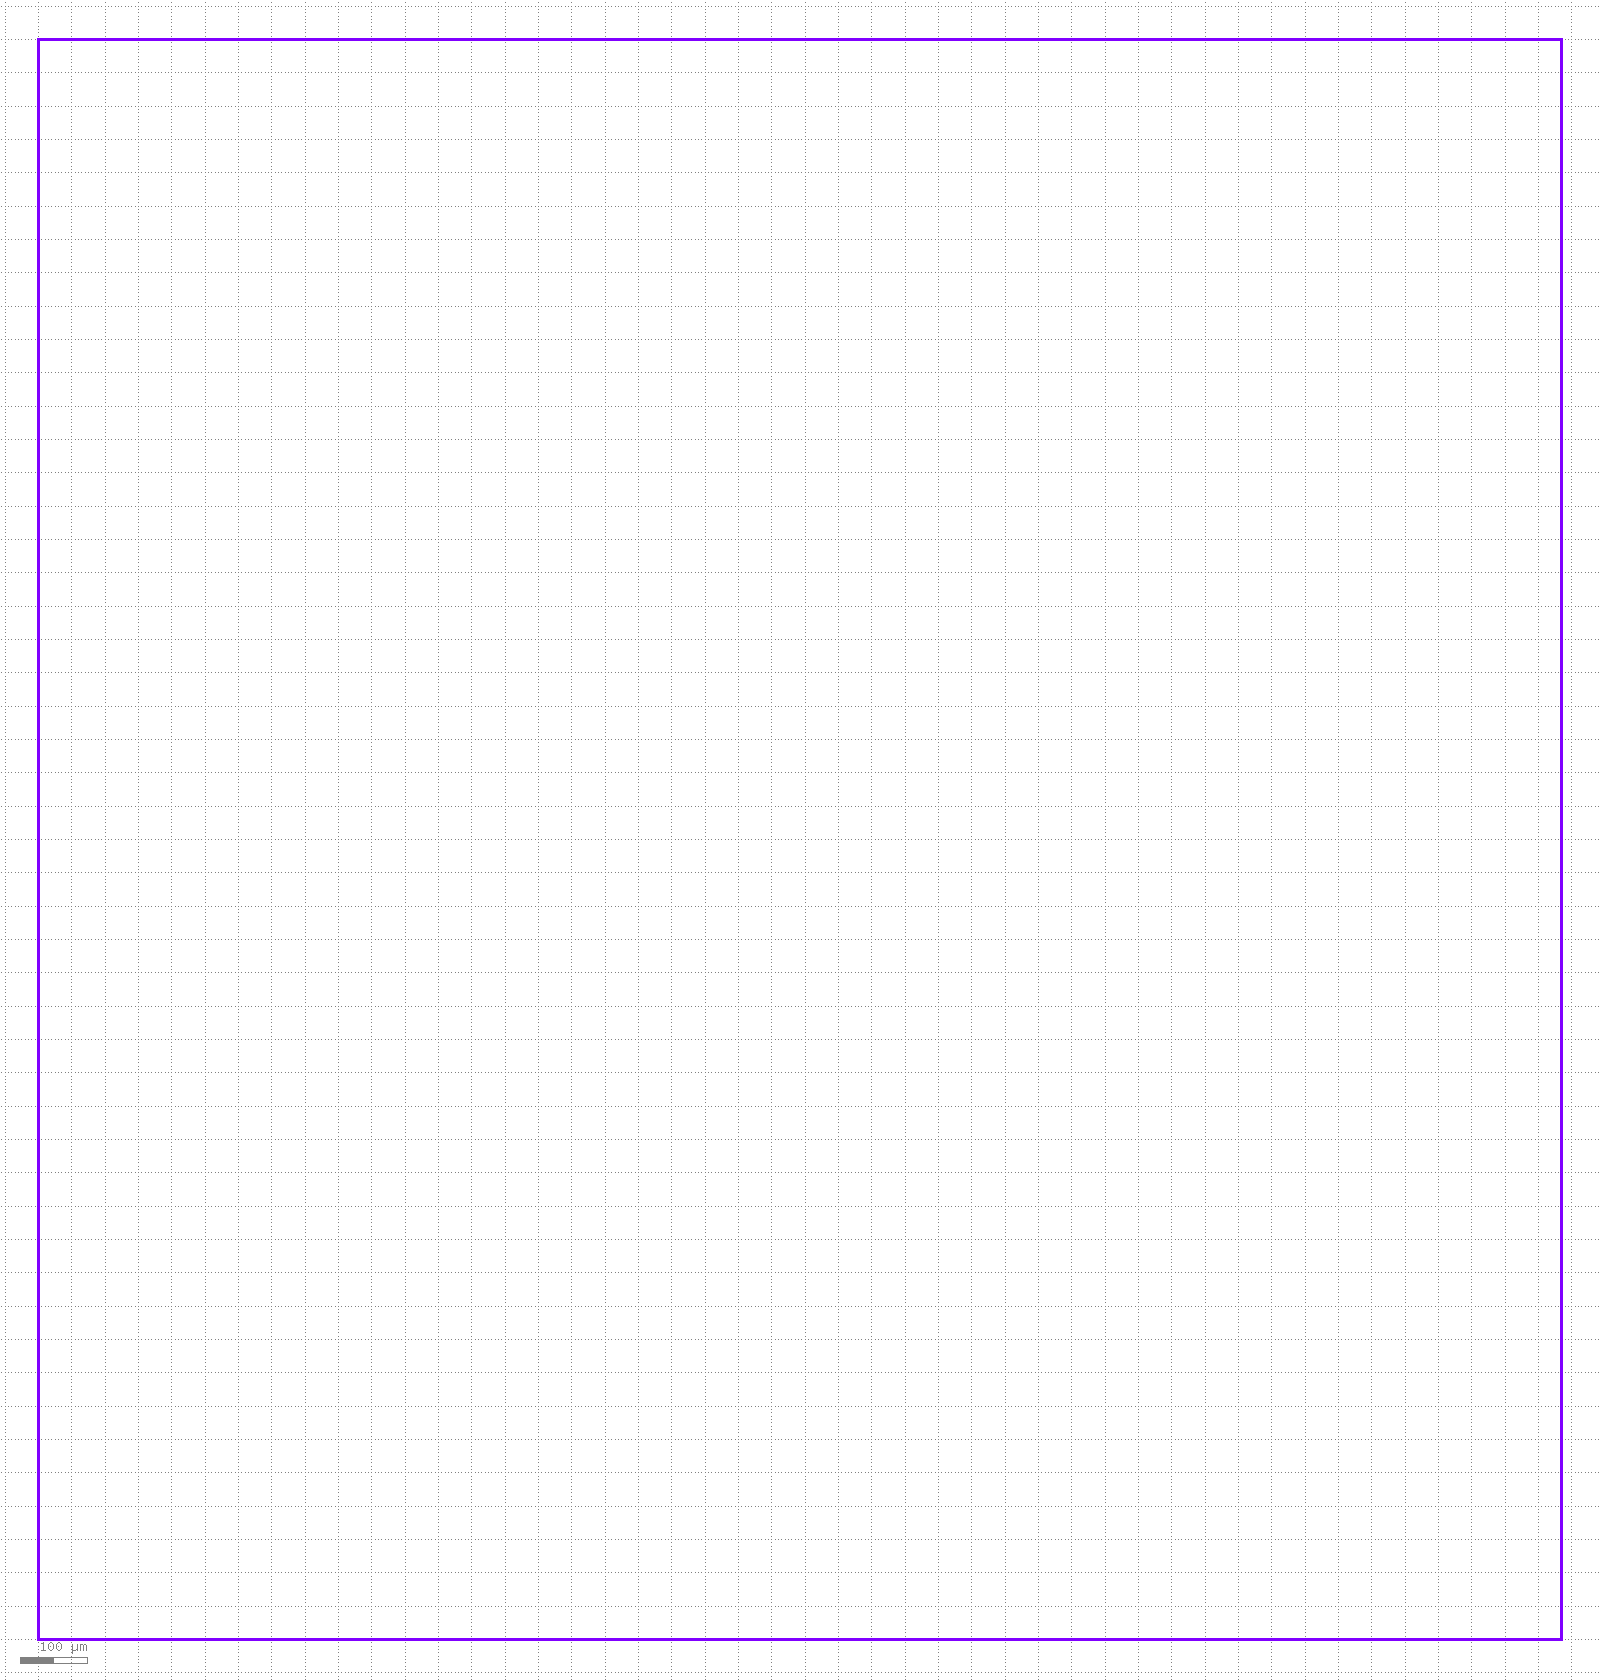

In [7]:
# Zoom out
# zoom_out(cell)
top_cell.show() # in KLayout GUI
top_cell.plot() # in the browser

In [8]:
# ============================================================
# Global/default GC settings
# Define once and reuse in later cells
# ============================================================
GC_SETTINGS = {
    "gc_cell_name": "SiEPICfab_1550TE",
    "gc_library": gclib_name,
    "gc_pitch": 127.0,   # microns
    "default_num_gc": 4,
    "label_location": 2,
}
WG_SETTINGS = {
    "wg_type": "Strip TE 1550 nm, w=500 nm (core-clad)",
}
device_prefix = "opt_in_TE_1550_device_JSong"

margin_x = 250

In [9]:
def gc_loopback(
    x_pos_GC=0,
    y_pos_GC=None,
    cellname="gc_loopback",
    device_label="opt_in_TE_1550_device_JSong_Loopback",
    xmax=None,
    num_gc=None,
    port_pairs= [(0, 1)],
    x_spacing=20.0,
    row_spacing=None,
    turtle_A=None,
):
    """
    Place a GC array and connect selected GC pairs with loopback waveguides.

    Parameters
    ----------
    x_pos_GC, y_pos_GC : float
        GC array anchor position in microns.

    cellname : str
        New cell name.

    device_label : str
        Label attached to the GC array.

    xmax : float
        Maximum x position before wrapping to next row.

    num_gc : int
        Number of GCs in the array.

    port_pairs : list of tuple[int, int]
        GC index pairs to connect.
        Examples:
            [(0, 1)]             -> connect GC0 and GC1
            [(0, 1), (2, 3)]     -> connect GC0-GC1 and GC2-GC3

    turtle_A : list or list of lists or None
        Routing path(s) for connect_pins_with_waveguide.
        - If a single list is given, use the same turtle for all pairs.
        - If a list of lists is given, each pair uses its own turtle.

    Returns
    -------
    next_x, next_y, xmax
    """

    global GC_SETTINGS, WG_SETTINGS, device_prefix, margin_x

    gc_cell_name   = GC_SETTINGS["gc_cell_name"]
    gc_library     = GC_SETTINGS["gc_library"]
    gc_pitch       = GC_SETTINGS["gc_pitch"]
    label_location = GC_SETTINGS["label_location"]

    if num_gc is None:
        num_gc = GC_SETTINGS["default_num_gc"]

    if y_pos_GC is None:
        y_pos_GC = top_cell.bbox().height() * dbu

    if xmax is None:
        xmax = top_cell.bbox().width() * dbu

    if row_spacing is None:
        row_spacing = (num_gc - 1) * gc_pitch + 2 * wg_bend_radius

    # if port_pairs is None:
    #     port_pairs = [(0, 1)]

    if turtle_A is None:
        turtle_A = []

    wg_type = WG_SETTINGS["wg_type"]
    gc_ports = ["opt1"] * num_gc

    if num_gc < 2:
        raise ValueError("num_gc must be at least 2")

    # validate port_pairs
    for pair in port_pairs:
        if len(pair) != 2:
            raise ValueError(f"Each entry in port_pairs must have 2 indices, got {pair}")
        i, j = pair
        if not (0 <= i < num_gc and 0 <= j < num_gc):
            raise ValueError(f"Invalid GC pair {pair} for num_gc={num_gc}")

    # normalize turtle_A
    # case 1: single turtle for all pairs, e.g. [50, -90, 127, 90, 50]
    # case 2: one turtle per pair, e.g. [[...], [...]]
    if len(port_pairs) == 1:
        turtle_list = [turtle_A]
    else:
        if isinstance(turtle_A, list) and len(turtle_A) > 0 and isinstance(turtle_A[0], list):
            if len(turtle_A) != len(port_pairs):
                raise ValueError("Number of turtle paths must match number of port pairs")
            turtle_list = turtle_A
        else:
            turtle_list = [turtle_A for _ in port_pairs]

    # -----------------------------
    # Create new cell
    # -----------------------------
    cell = ly.create_cell(cellname)
    top_cell.insert(CellInstArray(cell.cell_index(), Trans(Trans.R0, 0, 0)))

    # -----------------------------
    # Load GC cell
    # -----------------------------
    cell_gc = create_cell2(ly, gc_cell_name, gc_library)
    if cell_gc is None:
        raise ValueError(f"Could not load GC cell '{gc_cell_name}' from library '{gc_library}'")

    # -----------------------------
    # Auto place first device near corners (top-left, top-right, bottom-left, bottom-right)
    # -----------------------------
    top_boundary = top_cell.bbox().height() * dbu
    bottom_boundary = 0
    left_boundary = 0
    right_boundary = xmax
    
    # Determine which corner we're near
    near_left = x_pos_GC < 100#xmax * 0.25
    near_right = x_pos_GC > xmax-150# * 0.75
    near_top = y_pos_GC > top_boundary-100# * 0.75
    near_bottom = y_pos_GC == 0 #top_boundary * 0.25
    
    if y_pos_GC == top_boundary or near_top:
        # Top corners
        y_pos_GC -= (num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2
        if x_pos_GC == 0 or near_left:
            # Top-left
            x_pos_GC = cell_gc.bbox().width() * dbu
            # y_pos_GC -= (num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2
        elif near_right:
            # Top-right
            x_pos_GC = xmax - cell_gc.bbox().width() * dbu
            # y_pos_GC -= (num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2
    elif near_bottom:
        # Bottom corners
        y_pos_GC += (1 - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2
        if near_left:
            # Bottom-left
            x_pos_GC = cell_gc.bbox().width() * dbu
            # y_pos_GC += (num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2
        elif near_right:
            # Bottom-right
            x_pos_GC = xmax - cell_gc.bbox().width() * dbu
            # y_pos_GC += (num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2

    # -----------------------------
    # Place GC array
    # -----------------------------
    inst_GCs = coupler_array(
        cell,
        cell_name=gc_cell_name,
        cell_library=gc_library,
        x_offset=x_pos_GC / dbu,
        y_offset=y_pos_GC / dbu,
        label=device_label,
        label_location=label_location,
        count=num_gc,
    )

    # -----------------------------
    # Connect selected GC pairs
    # -----------------------------
    for (i, j), turtle in zip(port_pairs, turtle_list):
        connect_pins_with_waveguide(
            inst_GCs[i], gc_ports[i],
            inst_GCs[j], gc_ports[j],
            # turtle_A=turtle,
            waveguide_type=wg_type,
            r=wg_bend_radius
        )

    # -----------------------------
    # Suggested next placement
    # -----------------------------
    next_x = cell.bbox().right * dbu + x_spacing + cell_gc.bbox().width() * dbu
    next_y = y_pos_GC

    if next_x + cell.bbox().width() * dbu > xmax:
        next_x = cell_gc.bbox().width() * dbu
        next_y = cell.bbox().bottom * dbu - row_spacing - cell_gc.bbox().height() * dbu / 2

    return next_x, next_y, xmax


In [10]:
def SelfDefineAlignment(
    x_pos_GC=0,
    y_pos_GC=None,
    cellname_suffix="LT",
    device_label_area="_Default",
    xmax=None,
    num_loopback=2,
    port_pairs_list=None,
    x_spacing=20.0,
    row_spacing=None,
):
    """
    Generate multiple loopback structures with a given prefix.

    Parameters
    ----------
    x_pos_GC, y_pos_GC : float
        Starting position in microns.

    cellname_prefix : str
        Prefix for cell names (e.g., "GC_loopback").

    device_label_area : str
        Label area suffix (e.g., "_Ladd").

    xmax : float
        Maximum x position before wrapping to next row.

    num_loopback : int
        Number of loopback structures to generate.

    port_pairs_list : list of list of tuple or None
        List of port_pairs for each loopback.
        If None, defaults to [(0, 1), (2, 3)] for all.

    x_spacing, row_spacing : float
        Spacing parameters passed to gc_loopback.

    Returns
    -------
    next_x, next_y, xmax
    """

    global GC_SETTINGS, WG_SETTINGS, device_prefix, top_cell, dbu, wg_bend_radius

    if y_pos_GC is None:
        y_pos_GC = top_cell.bbox().height() * dbu

    if xmax is None:
        xmax = top_cell.bbox().width() * dbu

    if port_pairs_list is None:
        port_pairs_list = [[(0, 1), (2, 3)] for _ in range(num_loopback)]

    # Ensure port_pairs_list has the right length
    if len(port_pairs_list) < num_loopback:
        port_pairs_list.extend([[(0, 1), (2, 3)] for _ in range(num_loopback - len(port_pairs_list))])

    # Generate each loopback structure
    for i in range(num_loopback):
        # Create numbered cell name
        cellname = f"GCloopback{cellname_suffix}{i+1}"

        x_pos_GC, y_pos_GC, xmax = gc_loopback(
            x_pos_GC=x_pos_GC,
            y_pos_GC=y_pos_GC,
            cellname=cellname,
            device_label=device_prefix + device_label_area + "_" + cellname,
            xmax=None,
            num_gc=None,
            port_pairs=port_pairs_list[i],
            x_spacing=x_spacing,
            row_spacing=row_spacing,
            turtle_A=None,
        )

    return x_pos_GC, y_pos_GC, xmax


In [11]:
def Allpass_single(
    x_pos_GC=0,
    y_pos_GC=None,
    x_initial=0,
    cellname="cellname",
    device_label="opt_in_TE_1550_device_JSong_OneS",
    xmax=None,
    num_gc=None,
    device_cell_name="AddDropRing",
    device_library=lib_name,
    device_params=None,
    device_x=None,
    device_y=None,
    gc_ports=None,
    wg_type = None,
    x_spacing=20.0,
    row_spacing=None,
    routing_to_device=None,
    routing_from_device=None,
):
    """
    Generic placement function for:
        GC array -> routing -> device -> routing

    Notes
    -----
    1. GC information is taken from the global GC_SETTINGS dictionary.
    2. This function assumes the device has optical ports such as opt1, opt2.
    3. The first and last GC are used for input/output by default.
    """

    global GC_SETTINGS, WG_SETTINGS

    if device_params is None:
        device_params = {"r": 10, 
                         "w": 0.5, 
                         "gap1": 1,
                         "gap2": 0.2,
                         "b": 30,
                         "d":0,
                         }

    # if gc_ports is None:
    #     gc_ports = ["opt1", "opt1"]

    if routing_to_device is None:
        routing_to_device = []

    if routing_from_device is None:
        routing_from_device = []

    # Use global GC settings
    gc_cell_name = GC_SETTINGS["gc_cell_name"]
    gc_library = GC_SETTINGS["gc_library"]
    gc_pitch = GC_SETTINGS["gc_pitch"]
    label_location = GC_SETTINGS["label_location"]


    if num_gc is None:
        num_gc = GC_SETTINGS["default_num_gc"]
    gc_ports = ["opt1"] * num_gc
    
    if wg_type is None:
        wg_type = WG_SETTINGS["wg_type"]

    if y_pos_GC is None:
        y_pos_GC = top_cell.bbox().height() * dbu

    if xmax is None:
        xmax = top_cell.bbox().width() * dbu

    if row_spacing is None:
        row_spacing = (num_gc - 1) * gc_pitch + 2 * wg_bend_radius

    # --------------------------------------------------------
    # Create new cell
    # --------------------------------------------------------
    cell = ly.create_cell(cellname)
    top_cell.insert(CellInstArray(cell.cell_index(), Trans(Trans.R0, 0, 0)))

    # --------------------------------------------------------
    # Load GC cell
    # --------------------------------------------------------
    cell_gc = create_cell2(ly, gc_cell_name, gc_library)

    # --------------------------------------------------------
    # Auto place first device near top-left
    # --------------------------------------------------------
    if x_pos_GC == 0 and y_pos_GC == top_cell.bbox().height() * dbu:
        x_pos_GC = int(cell_gc.bbox().width() * dbu)
        y_pos_GC -= int((num_gc - 1) * gc_pitch + cell_gc.bbox().height() * dbu / 2)

    # --------------------------------------------------------
    # Place GC array
    # --------------------------------------------------------
    inst_GCs = coupler_array(
        cell,
        cell_name=gc_cell_name,
        cell_library=gc_library,
        x_offset=x_pos_GC / dbu,
        y_offset=y_pos_GC / dbu,
        label=device_label,
        label_location=label_location,
        count=num_gc,
    )

    if num_gc < 2:
        raise ValueError("num_gc must be at least 2.")

    # --------------------------------------------------------
    # Create / load device cell
    # If device_params is given, treat as PCell
    # Otherwise load as normal library cell
    # --------------------------------------------------------
    if device_params:
        cell_device = ly.create_cell(
            device_cell_name,
            device_library,
            device_params
        )
    else:
        cell_device = create_cell2(ly, device_cell_name, device_library)

    if cell_device is None:
        raise ValueError(
            f"Could not create/load device cell: "
            f"name='{device_cell_name}', library='{device_library}', params={device_params}"
        )

    # --------------------------------------------------------
    # Default device position
    # --------------------------------------------------------
    if device_x is None:
        device_x = inst_GCs[1].bbox().right * dbu + 2 * wg_bend_radius

    if device_y is None:
        device_y = inst_GCs[0].bbox().center().y * dbu - 0.5 * gc_pitch

    gc1 = inst_GCs[1]

    # print("left   =", gc1.bbox().left * dbu)
    # print("right  =", gc1.bbox().right * dbu)
    # print("bottom =", gc1.bbox().bottom * dbu)
    # print("top    =", gc1.bbox().top * dbu)

    # print("center x =", gc1.bbox().center().x * dbu)
    # print("center y =", gc1.bbox().center().y * dbu)

    t_dev = Trans(
        Trans.R270,
        device_x / dbu,
        device_y / dbu
    )
    inst_device = cell.insert(CellInstArray(cell_device.cell_index(), t_dev))

    # inst_device = connect_cell(inst_GCs[1], "opt1", cell_device, "opt1",translation=device_rotation)
    # inst_device.transform(Trans(50/dbu,0))
    # --------------------------------------------------------
    # Route GC[1] to device input
    # --------------------------------------------------------
    # connect_pins_with_waveguide(
    #     inst_GCs[3], gc_ports[3],
    #     inst_GCs[2], gc_ports[2],
    #     # turtle_A=routing_to_device,
    #     waveguide_type=wg_type,
    #     # r=wg_bend_radius
    # )
    
    connect_pins_with_waveguide(
        inst_GCs[1], gc_ports[1],
        inst_device, "opt2",
        # inst_GCs[1], gc_ports[1],
        # turtle_A=routing_to_device,
        waveguide_type=wg_type,
        # r=wg_bend_radius
    )

    # # --------------------------------------------------------
    # # Route device output to GC[-1]
    # # --------------------------------------------------------
    connect_pins_with_waveguide(
        # inst_device, "opt2",
        inst_GCs[0], gc_ports[0],
        inst_device, "opt1",

        # turtle_A=routing_from_device,
        waveguide_type=wg_type,
        r=wg_bend_radius
    )

    # connect_pins_with_waveguide(
    #     # inst_device, "opt2",
    #     inst_GCs[2], gc_ports[2],
    #     inst_device, "opt3",

    #     # turtle_A=routing_from_device,
    #     waveguide_type=wg_type,
    #     r=wg_bend_radius
    # )
    
    # connect_pins_with_waveguide(
    #     # inst_device, "opt2",
    #     inst_GCs[3], gc_ports[3],
    #     inst_device, "opt1",

    #     # turtle_A=routing_from_device,
    #     waveguide_type=wg_type,
    #     r=wg_bend_radius
    # )
    # --------------------------------------------------------
    # Suggested next placement position
    # --------------------------------------------------------
    next_x = cell.bbox().right * dbu + x_spacing + cell_gc.bbox().width() * dbu
    next_y = y_pos_GC

    if next_x + cell.bbox().width() * dbu > xmax - margin_x:
        next_x = x_initial#cell_gc.bbox().width() * dbu
        next_y = cell.bbox().bottom * dbu - row_spacing - cell_gc.bbox().height() * dbu / 2
        # next_y = cell.bbox().top * dbu - 900

    return next_x, next_y, xmax

In [12]:
# x = 0
# y = top_cell.bbox().height() * dbu
# xmax = top_cell.bbox().width() * dbu
# print(f"Starting position: x={x} um, y={y} um, xmax={xmax} um")
# y_initial = y

# x,y,x_max =  Allpass_single(
#     x_pos_GC=x,
#     y_pos_GC=y,
#     cellname="cellname",
#     device_label="opt_in_TE_1550_device_JSong_OneS",
#     xmax=xmax,
#     num_gc=4,
#     device_cell_name="AddDropRing",
#     device_library=lib_name,
#     device_params=None,
#     device_x=None,
#     device_y=None,
#     gc_ports=None,
#     wg_type = None,
#     x_spacing=20.0,
#     row_spacing=None,
#     routing_to_device=None,
#     routing_from_device=None,
# )
# top_cell.show()
# top_cell.plot()

Starting position: x=0 um, y=2400.0 um, xmax=2285.0 um
Gap sequence: [0.1   0.125 0.15  0.175 0.2   0.225 0.25  0.275 0.3   0.325 0.35  0.375
 0.4   0.425 0.45  0.475 0.5  ]
Could not connect to klive server. Is klayout open and klive plugin installed?


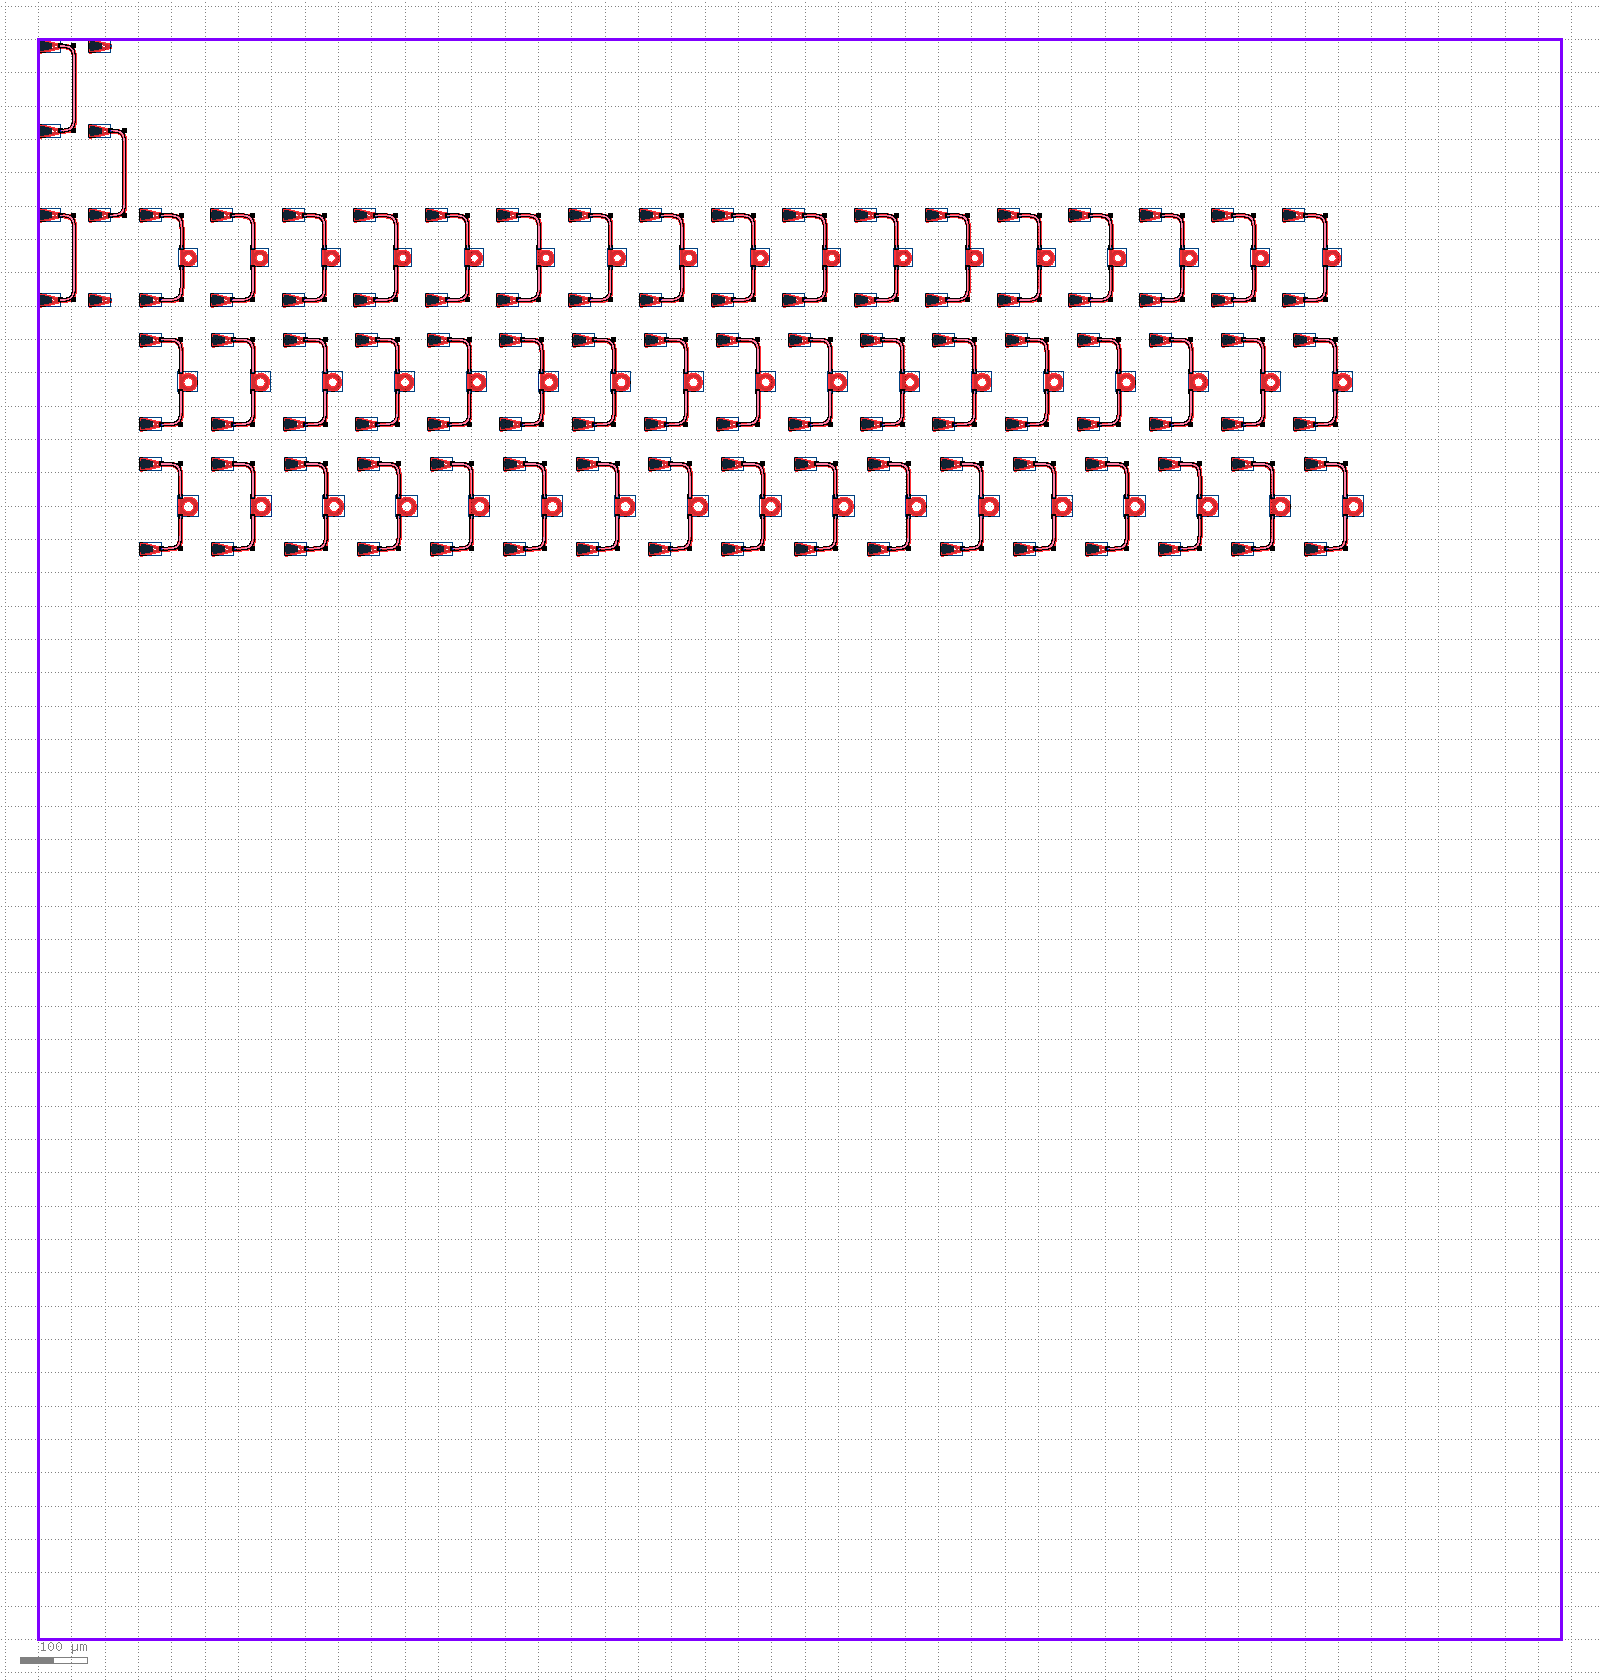

In [ ]:
# Start near top-left of floorplan
device_label_area = "_SinglePassRing"
x = 0
y = top_cell.bbox().height() * dbu
xmax = top_cell.bbox().width() * dbu
print(f"Starting position: x={x} um, y={y} um, xmax={xmax} um")
y_initial = y

# Generate loopback alignment structures
x, y, xmax = SelfDefineAlignment(
    x_pos_GC=x,
    y_pos_GC=y,
    cellname_suffix="LT",
    device_label_area=device_label_area,
    xmax=xmax,
    num_loopback=2,
    port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
    x_spacing=20.0,
    row_spacing=None,
)

# Define device sequence and gap sweep
device_cell_name_sequence = [
    "AddDropRing",
]

x_initial = x
N_repeat = 1  # Number of times to repeat the identical device setss
ring_radius_sequence = [9, 10, 11]  # Ring radii to sweep
gap_sequence = np.linspace(0.1, 0.5, num=17)  # Gap sequence from 0.1 to 0.5 microns

print(f"Gap sequence: {gap_sequence}")

for repeat_idx in range(N_repeat):  # OUTERMOST - repeat the entire set
    for r_idx, ring_radius in enumerate(ring_radius_sequence, start=1):
        for gap_idx, gap in enumerate(gap_sequence, start=1):
            for i, dev_name in enumerate(device_cell_name_sequence, start=1):
                cellname = f"R{ring_radius:.0f}gap{gap*1e3:.0f}_rep{repeat_idx+1}"
                label = device_prefix + device_label_area + f"_"+cellname
                
                device_params = {
                    "r": ring_radius,
                    "w": 0.5,
                    "gap1": gap,  # Sweep gap1
                    "gap2": gap,
                    "b": 30,
                    "d": 0,
                }
                
                x, y, x_max = Allpass_single(
                    x_pos_GC=x,
                    y_pos_GC=y,
                    x_initial = x_initial,
                    cellname=cellname,
                    device_label=label,
                    xmax=xmax,
                    num_gc=2,
                    device_cell_name="AddDropRing",
                    device_library=lib_name,
                    device_params=device_params,
                    device_x=None,
                    device_y=None,
                    gc_ports=None,
                    wg_type=None,
                    x_spacing=20.0,
                    row_spacing=None,
                    routing_to_device=None,
                    routing_from_device=None,
                )

top_cell.show()
top_cell.plot()


Could not connect to klive server. Is klayout open and klive plugin installed?


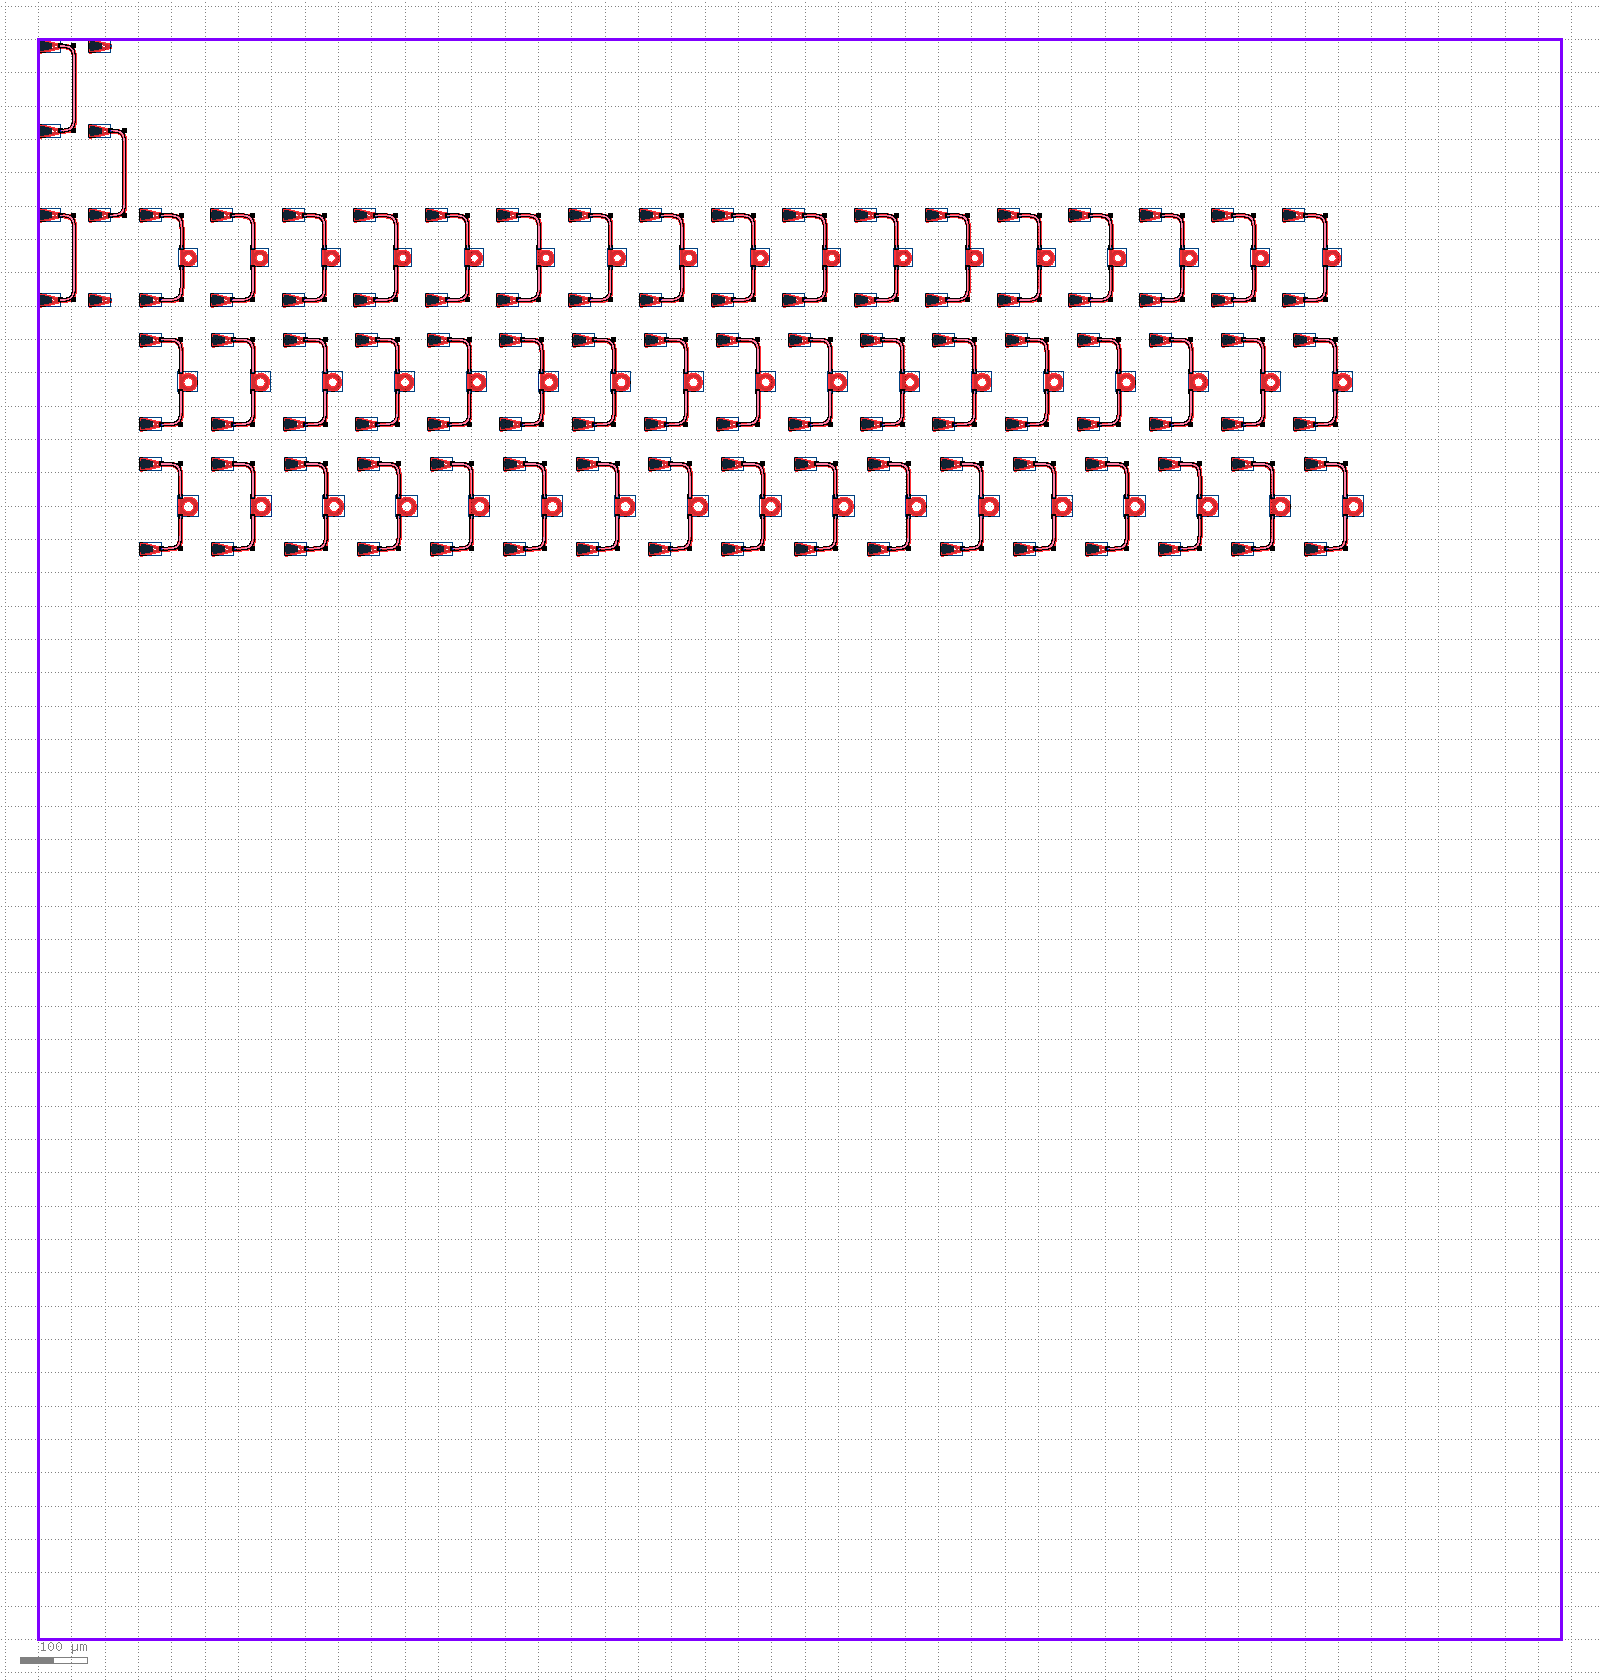

In [14]:
top_cell.show()
top_cell.plot()


Could not connect to klive server. Is klayout open and klive plugin installed?


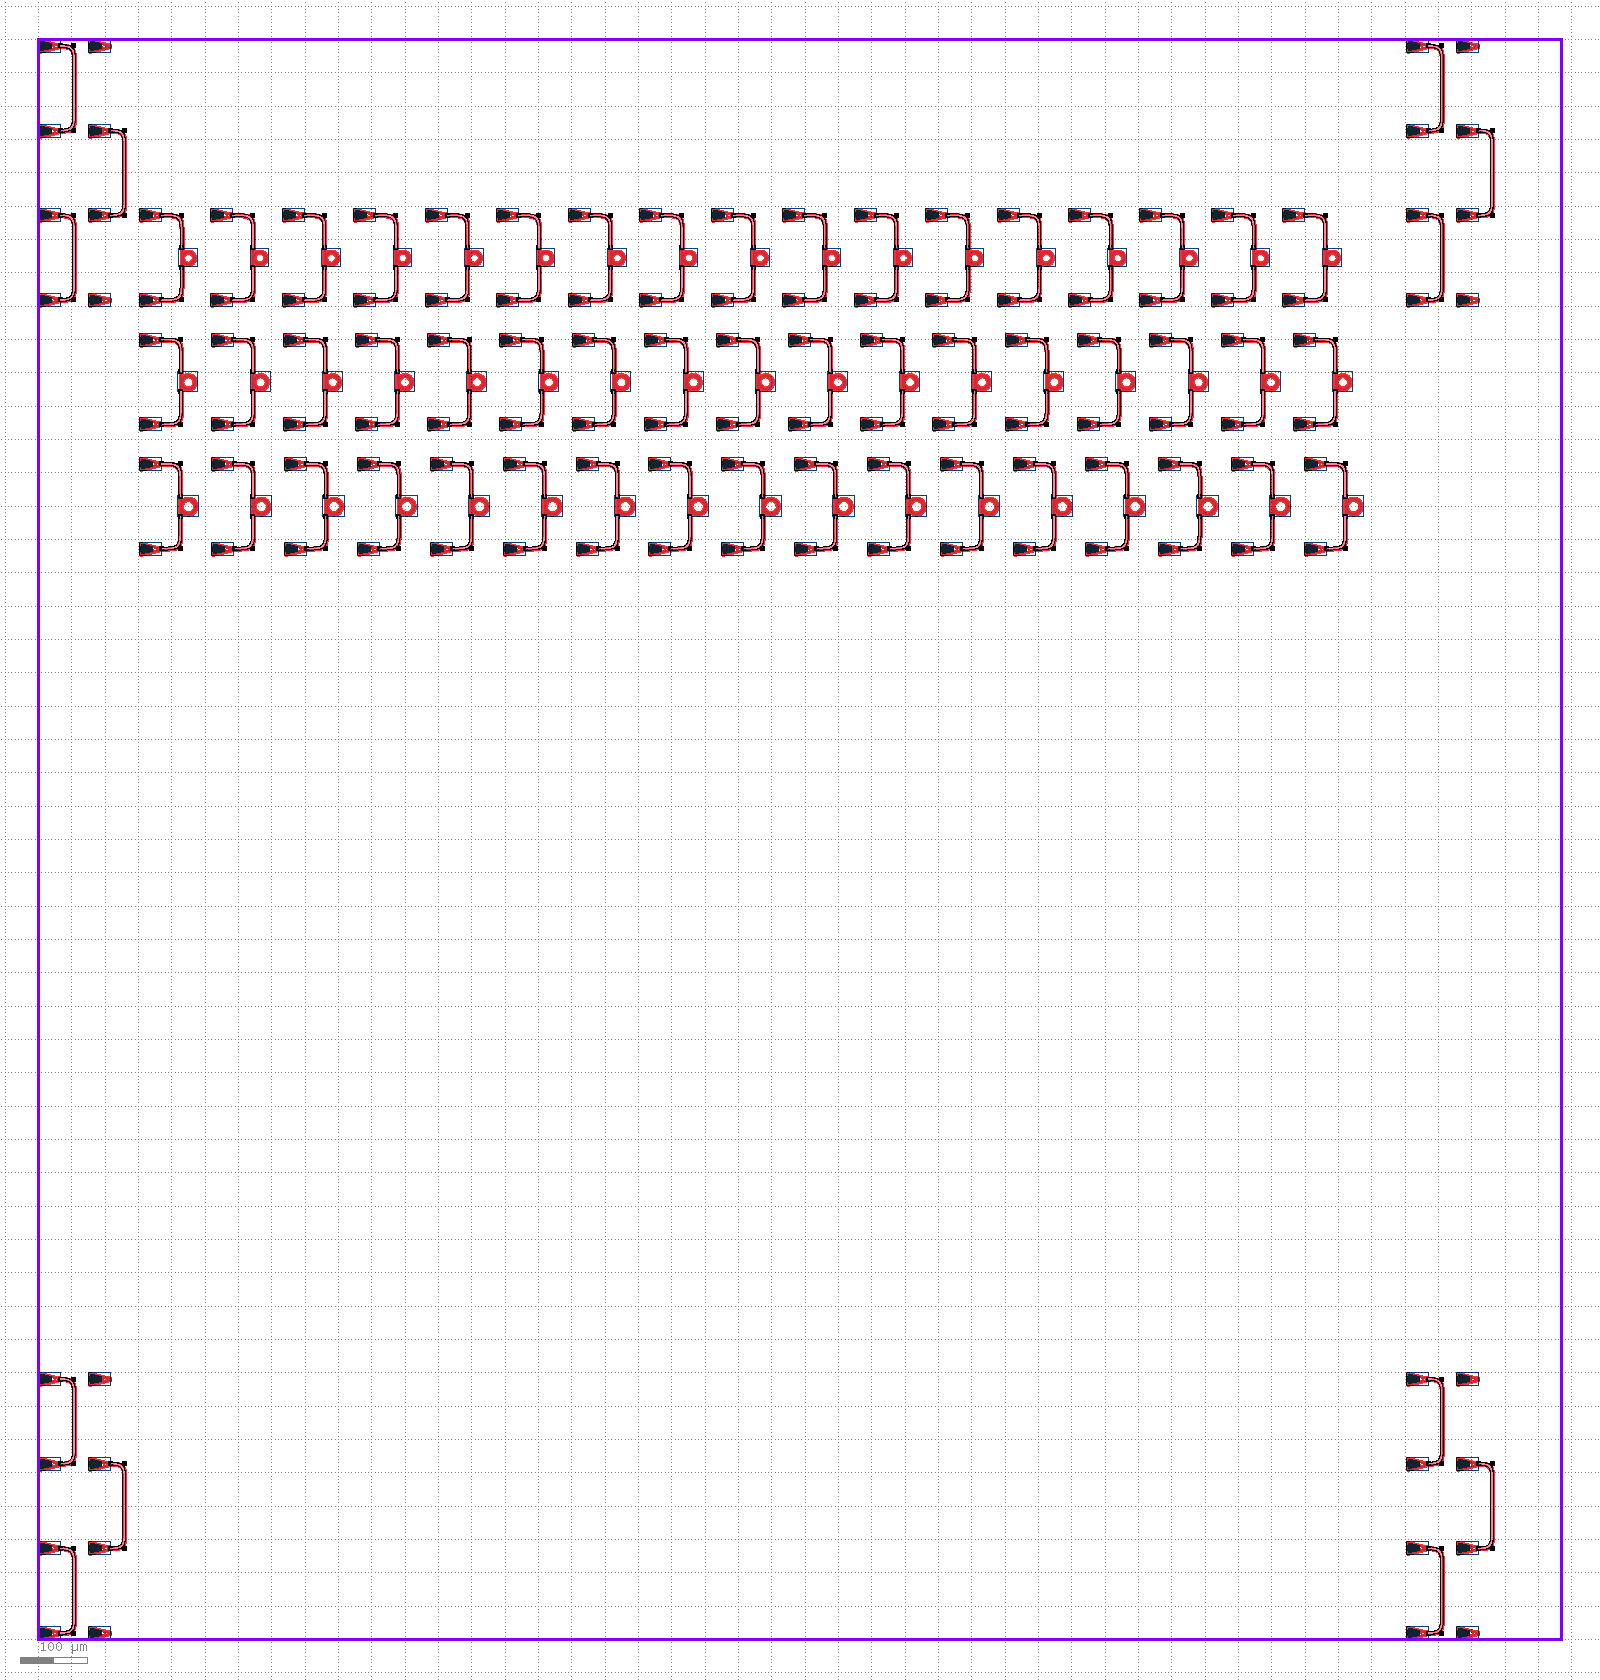

In [15]:

# Generate right-side loopback alignment structures at the same y as left-side
_, _, _ = SelfDefineAlignment(
    x_pos_GC=xmax-200,
    y_pos_GC=y_initial,
    cellname_suffix="RT",
    device_label_area=device_label_area,
    xmax=xmax,
    num_loopback=2,
    port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
    x_spacing=20.0,
    row_spacing=None,
)
# top_cell.show()
# top_cell.plot()


# Generate right-side loopback alignment structures at the same y as left-side
_, _, _ = SelfDefineAlignment(
    x_pos_GC=0,
    y_pos_GC=0,
    cellname_suffix="LB",
    device_label_area=device_label_area,
    xmax=xmax,
    num_loopback=2,
    port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
    x_spacing=20.0,
    row_spacing=None,
)

_, _, _ = SelfDefineAlignment(
    x_pos_GC=xmax-200,
    y_pos_GC=0,
    cellname_suffix="RB",
    device_label_area=device_label_area,
    xmax=xmax,
    num_loopback=2,
    port_pairs_list=[[(0, 1), (2, 3)], [(1, 2)]],
    x_spacing=20.0,
    row_spacing=None,
)


top_cell.show()
top_cell.plot()


In [16]:
from  SiEPICfab_ZEP_export import export_for_fabrication


gds_in = os.path.join("gds_in\\", f"{top_cell_name}")


export_for_fabrication(ly, top_cell, gds_in, flatten=True)

 - Warning: You may only have one top cell in your hierarchy. Clean up using SiEPIC > Layout > Delete Extra Top Cells.
 - Warning: Exporting top cell: SinglePassRing
 - cell: SinglePassRing
saving output OASIS: gds_in\SinglePassRing_static.oas
Success. Layout exported successfully: 
gds_in\SinglePassRing_static.oas
